<a href="https://colab.research.google.com/github/Amadi200/montra_hospitality/blob/main/08_business_insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIENCE BUSINESS **INSIGHTS**

In [1]:
# !pip install -q pandas pyarrow matplotlib seaborn plotly

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.1f}".format)

Mount Drive & Load Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment/reviews_with_topic_sentiment.parquet"
df = pd.read_parquet(DATA_PATH)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Mounted at /content/drive
Shape: (34536, 31)
Columns: ['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'bk_guest_id', 'bk_hotel_id', 'bk_room_type', 'bk_booking_channel', 'bk_check_in_date', 'bk_check_out_date', 'bk_total_amount', 'bk_stay_duration', 'gt_customer_type', 'gt_loyalty_status', 'gt_country', 'gt_previous_stays', 'ht_hotel_name', 'ht_location', 'ht_star_rating', 'ht_total_rooms', 'review_text_ml', 'text_length', 'word_count', 'topic', 'topic_probability', 'sentiment', 'sentiment_score']


Basic Preparation

In [3]:
if "sentiment" not in df.columns and "sentiment_label" in df.columns:
    df["sentiment"] = df["sentiment_label"]

# Convert date columns
for col in df.columns:
    if "date" in col.lower():
        df[col] = pd.to_datetime(df[col], errors="coerce")

Business-Friendly Topic Naming

In [4]:
# You can manually improve these names after looking at topic_info.csv
topic_name_map = {
    -1: "Outliers / Mixed Feedback",
    0: "Staff Service & Friendliness",
    1: "Room Cleanliness",
    2: "Location & Accessibility",
    3: "Breakfast & Food Quality",
    4: "Room Comfort & Bed Quality",
    5: "Check-in / Check-out Experience",
    6: "Facilities & Amenities",
    7: "Value for Money / Pricing",
    8: "Bathroom & Toiletries",
    9: "Noise Levels",
    10: "WiFi & Connectivity",
    # Add more as needed after reviewing your topics
}

df["topic_name"] = df["topic"].map(topic_name_map).fillna(df["topic"].apply(lambda x: f"Topic {x}"))

print("\nTopic names applied.")
print(df["topic_name"].value_counts().head(12))


Topic names applied.
topic_name
Staff Service & Friendliness       17834
Outliers / Mixed Feedback           4406
Room Cleanliness                    1098
Location & Accessibility            1064
Breakfast & Food Quality             803
Room Comfort & Bed Quality           775
Check-in / Check-out Experience      729
Facilities & Amenities               667
Value for Money / Pricing            568
Bathroom & Toiletries                514
Noise Levels                         475
WiFi & Connectivity                  430
Name: count, dtype: int64


Overall Snapshot

In [5]:
print("\n" + "="*70)
print("1. OVERALL GUEST EXPERIENCE SNAPSHOT")
print("="*70)

print("\nSentiment Distribution (%):")
print(df["sentiment"].value_counts(normalize=True).mul(100).round(1))

if "rating_score" in df.columns:
    print(f"\nAverage Rating: {df['rating_score'].mean():.2f}")


1. OVERALL GUEST EXPERIENCE SNAPSHOT

Sentiment Distribution (%):
sentiment
Positive   62.2
Negative   29.3
Neutral     8.5
Name: proportion, dtype: float64

Average Rating: 3.03


Topic-Level Insights

In [6]:
print("\n" + "="*70)
print("2. TOPIC-LEVEL SENTIMENT INSIGHTS")
print("="*70)

topic_insights = (
    df.groupby(["topic", "topic_name"])
    .agg(
        reviews      = ("review_text", "count"),
        positive_pct = ("sentiment", lambda x: (x == "Positive").mean() * 100),
        neutral_pct  = ("sentiment", lambda x: (x == "Neutral").mean() * 100),
        negative_pct = ("sentiment", lambda x: (x == "Negative").mean() * 100),
        avg_rating   = ("rating_score", "mean") if "rating_score" in df.columns else ("review_text", "count")
    )
    .reset_index()
    .sort_values("reviews", ascending=False)
)

topic_insights[["positive_pct", "neutral_pct", "negative_pct"]] = topic_insights[
    ["positive_pct", "neutral_pct", "negative_pct"]
].round(1)

display(topic_insights.head(15))


2. TOPIC-LEVEL SENTIMENT INSIGHTS


,topic,topic_name,reviews,positive_pct,neutral_pct,negative_pct,avg_rating
1,0,Staff Service & Friendliness,17834,62.5,8.3,29.3,3.0
0,-1,Outliers / Mixed Feedback,4406,57.9,7.4,34.7,3.0
2,1,Room Cleanliness,1098,63.2,6.8,30.0,3.0
3,2,Location & Accessibility,1064,52.8,15.3,31.9,2.9
4,3,Breakfast & Food Quality,803,64.9,6.1,29.0,3.0
5,4,Room Comfort & Bed Quality,775,66.5,5.7,27.9,3.0
6,5,Check-in / Check-out Experience,729,65.6,6.2,28.3,3.1
7,6,Facilities & Amenities,667,63.1,7.3,29.5,3.0
8,7,Value for Money / Pricing,568,69.5,3.7,26.8,3.0
9,8,Bathroom & Toiletries,514,57.8,28.8,13.4,3.2


Top Pain Points & Strengths

In [7]:
print("\n" + "="*70)
print("3. TOP PAIN POINTS (Priority Issues)")
print("="*70)

pain = topic_insights[(topic_insights["topic"] != -1) & (topic_insights["reviews"] >= 40)].copy()
pain["pain_score"] = pain["negative_pct"] * np.log1p(pain["reviews"])
pain = pain.sort_values("pain_score", ascending=False)

display(pain[["topic_name", "reviews", "negative_pct", "positive_pct", "avg_rating"]].head(10))

print("\n" + "="*70)
print("4. TOP STRENGTHS (What Guests Love)")
print("="*70)

strength = topic_insights[(topic_insights["topic"] != -1) & (topic_insights["reviews"] >= 40)].copy()
strength["strength_score"] = strength["positive_pct"] * np.log1p(strength["reviews"])
strength = strength.sort_values("strength_score", ascending=False)

display(strength[["topic_name", "reviews", "positive_pct", "negative_pct", "avg_rating"]].head(10))


3. TOP PAIN POINTS (Priority Issues)


,topic_name,reviews,negative_pct,positive_pct,avg_rating
31,Topic 30,116,98.3,0.9,1.9
34,Topic 33,78,96.2,0.0,1.8
35,Topic 34,72,97.2,0.0,1.9
40,Topic 39,41,100.0,0.0,1.8
21,Topic 20,204,64.7,22.1,2.3
1,Staff Service & Friendliness,17834,29.3,62.5,3.0
36,Topic 35,63,61.9,17.5,2.2
12,Topic 11,401,41.4,44.1,2.8
15,Topic 14,339,39.2,54.3,3.0
3,Location & Accessibility,1064,31.9,52.8,2.9



4. TOP STRENGTHS (What Guests Love)


,topic_name,reviews,positive_pct,negative_pct,avg_rating
1,Staff Service & Friendliness,17834,62.5,29.3,3.0
19,Topic 18,231,99.6,0.0,4.1
22,Topic 21,185,100.0,0.0,4.1
11,WiFi & Connectivity,430,77.2,16.5,3.2
10,Noise Levels,475,74.7,21.5,3.1
28,Topic 27,136,91.9,2.9,3.2
2,Room Cleanliness,1098,63.2,30.0,3.0
5,Room Comfort & Bed Quality,775,66.5,27.9,3.0
8,Value for Money / Pricing,568,69.5,26.8,3.0
14,Topic 13,384,73.7,23.7,3.0


Hotel / Location Performance

In [8]:
print("\n" + "="*70)
print("5. PERFORMANCE BY HOTEL / LOCATION")
print("="*70)

hotel_col = next((c for c in ["ht_hotel_name", "hotel_name", "hotel_id"] if c in df.columns), None)
location_col = next((c for c in ["ht_location", "location", "gt_country"] if c in df.columns), None)

if hotel_col:
    hotel_perf = (
        df.groupby(hotel_col)
        .agg(
            reviews      = ("review_text", "count"),
            positive_pct = ("sentiment", lambda x: (x == "Positive").mean() * 100),
            negative_pct = ("sentiment", lambda x: (x == "Negative").mean() * 100),
            avg_rating   = ("rating_score", "mean") if "rating_score" in df.columns else ("review_text", "count")
        )
        .round(1)
        .sort_values("reviews", ascending=False)
    )
    display(hotel_perf.head(12))
else:
    print("No hotel column found.")


5. PERFORMANCE BY HOTEL / LOCATION


,reviews,positive_pct,negative_pct,avg_rating
ht_hotel_name,,,,
Edinburgh Riverside Hotel,2876,55.5,35.9,2.8
Southampton Park Hotel,1440,63.1,28.1,3.1
Nottingham Riverside Hotel,1424,74.1,18.8,3.4
Glasgow Skyline Hotel,1419,54.8,36.3,2.8
Nottingham Park Hotel,1412,65.4,25.4,3.1
The Belfast Heritage,1411,63.4,28.3,3.1
Glasgow Metropolitan,1410,64.3,26.5,3.1
Manchester Metropolitan,1405,55.5,34.0,2.9
The London Boutique,1397,64.6,25.6,3.1


Customer Segment Insights

In [9]:
print("\n" + "="*70)
print("6. INSIGHTS BY CUSTOMER SEGMENT")
print("="*70)

segment_cols = [c for c in ["gt_customer_type", "gt_loyalty_status", "gt_country", "bk_booking_channel"] if c in df.columns]

for col in segment_cols:
    print(f"\n--- By {col} ---")
    seg = (
        df.groupby(col)
        .agg(
            reviews      = ("review_text", "count"),
            positive_pct = ("sentiment", lambda x: (x == "Positive").mean() * 100),
            negative_pct = ("sentiment", lambda x: (x == "Negative").mean() * 100)
        )
        .round(1)
        .sort_values("reviews", ascending=False)
    )
    display(seg.head(10))


6. INSIGHTS BY CUSTOMER SEGMENT

--- By gt_customer_type ---


,reviews,positive_pct,negative_pct
gt_customer_type,,,
Leisure,13821,62.4,28.9
Business,8303,62.1,30.2
Corporate,5445,61.7,29.6
Group,3512,61.3,29.8
Family,3455,63.6,27.8



--- By gt_loyalty_status ---


,reviews,positive_pct,negative_pct
gt_loyalty_status,,,
None,17388,62.3,29.2
Silver,8502,62.7,28.9
Gold,5766,61.1,30.4
Platinum,2880,62.3,29.2



--- By gt_country ---


,reviews,positive_pct,negative_pct
gt_country,,,
United Kingdom,12071,62.1,29.3
United States,4198,62.3,29.5
Nigeria,3409,62.7,28.7
Germany,2525,61.9,29.5
France,2001,60.9,29.3
Spain,1894,63.4,29.1
Ireland,1789,61.3,29.9
Netherlands,1674,63.6,27.8
United Arab Emirates,1345,62.0,30.3



--- By bk_booking_channel ---


,reviews,positive_pct,negative_pct
bk_booking_channel,,,
Direct Website,8567,62.0,29.4
Booking.com,7692,62.7,29.1
Expedia,5206,62.9,28.4
Travel Agent,3481,60.5,30.4
Airbnb,3376,62.1,29.7
Corporate Portal,3369,63.3,28.9
Walk-in,2845,61.4,30.0


Time Trend (if date available)

In [10]:
date_col = next((c for c in df.columns if "review_date" in c.lower() or c.lower() == "date"), None)

if date_col and df[date_col].notna().sum() > 100:
    print("\n" + "="*70)
    print("7. SENTIMENT TREND OVER TIME")
    print("="*70)

    df["month"] = df[date_col].dt.to_period("M").astype(str)
    trend = (
        df.groupby("month")["sentiment"]
        .value_counts(normalize=True)
        .mul(100)
        .unstack(fill_value=0)
        .round(1)
    )
    display(trend.tail(12))


7. SENTIMENT TREND OVER TIME


sentiment,Negative,Neutral,Positive
month,,,
2025-07,29.5,8.4,62.0
2025-08,27.7,8.8,63.5
2025-09,29.7,7.9,62.4
2025-10,31.3,7.1,61.6
2025-11,29.6,8.9,61.5
2025-12,28.6,8.0,63.4
2026-01,26.8,8.4,64.8
2026-02,29.8,8.6,61.6
2026-03,28.5,9.4,62.0


Executive Summary

In [11]:
print("\n" + "="*70)
print("8. EXECUTIVE SUMMARY – KEY TAKEAWAYS")
print("="*70)

total_reviews = len(df)
pos_pct = (df["sentiment"] == "Positive").mean() * 100
neg_pct = (df["sentiment"] == "Negative").mean() * 100

top_pain = pain.iloc[0]["topic_name"] if len(pain) > 0 else "N/A"
top_strength = strength.iloc[0]["topic_name"] if len(strength) > 0 else "N/A"

print(f"""
• Total reviews analysed: {total_reviews:,}
• Overall Positive sentiment: {pos_pct:.1f}%
• Overall Negative sentiment: {neg_pct:.1f}%

• Biggest strength : {top_strength}
• Biggest pain point: {top_pain}

Recommendations:
1. Prioritise improvement actions on the top 3 pain points (highest volume + negativity).
2. Protect and promote the top strengths in marketing and staff training.
3. Investigate underperforming hotels/locations for targeted operational support.
4. Monitor sentiment trends monthly to detect emerging issues early.
""")


8. EXECUTIVE SUMMARY – KEY TAKEAWAYS

• Total reviews analysed: 34,536
• Overall Positive sentiment: 62.2%
• Overall Negative sentiment: 29.3%

• Biggest strength : Staff Service & Friendliness
• Biggest pain point: Topic 30

Recommendations:
1. Prioritise improvement actions on the top 3 pain points (highest volume + negativity).
2. Protect and promote the top strengths in marketing and staff training.
3. Investigate underperforming hotels/locations for targeted operational support.
4. Monitor sentiment trends monthly to detect emerging issues early.



Visualisations

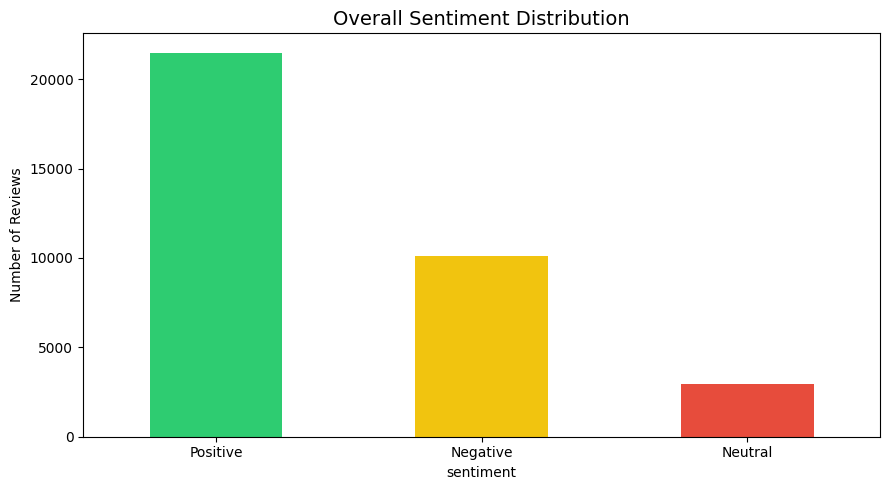

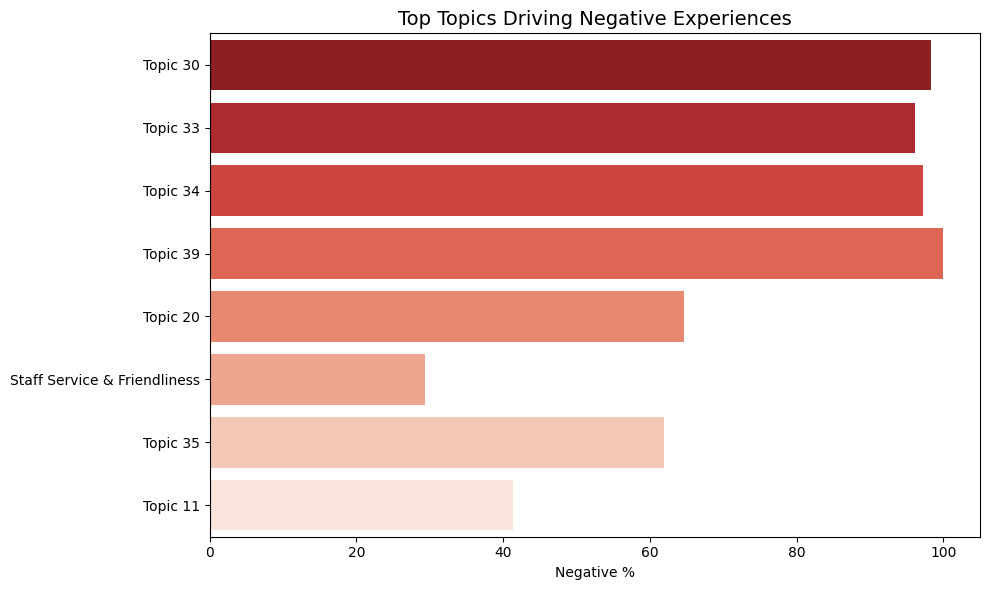

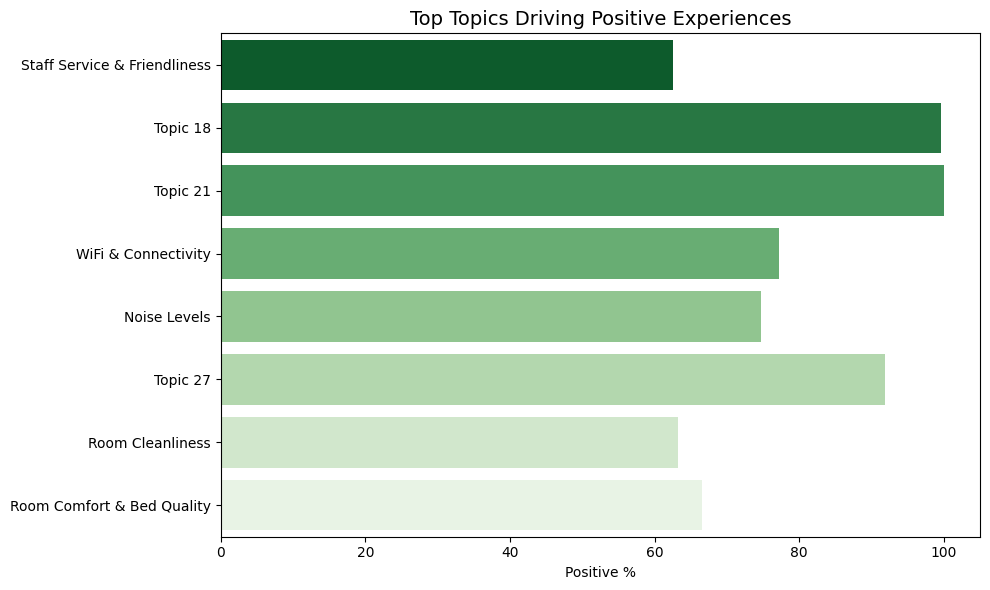

In [12]:
plt.figure(figsize=(9, 5))
df["sentiment"].value_counts().plot(kind="bar", color=["#2ecc71", "#f1c40f", "#e74c3c"])
plt.title("Overall Sentiment Distribution", fontsize=14)
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=pain.head(8), x="negative_pct", y="topic_name", palette="Reds_r")
plt.title("Top Topics Driving Negative Experiences", fontsize=14)
plt.xlabel("Negative %")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=strength.head(8), x="positive_pct", y="topic_name", palette="Greens_r")
plt.title("Top Topics Driving Positive Experiences", fontsize=14)
plt.xlabel("Positive %")
plt.ylabel("")
plt.tight_layout()
plt.show()

Save Everything

In [13]:
output_dir = Path("/content/drive/MyDrive/Montra_Hospitality/outputs/business_insights")
output_dir.mkdir(parents=True, exist_ok=True)

topic_insights.to_csv(output_dir / "topic_level_insights.csv", index=False)
pain.to_csv(output_dir / "top_pain_points.csv", index=False)
strength.to_csv(output_dir / "top_strengths.csv", index=False)

if hotel_col:
    hotel_perf.to_csv(output_dir / "hotel_performance.csv")

df.to_parquet(output_dir / "full_guest_experience_data.parquet", index=False)

print(f"\nAll business insights saved to:\n{output_dir}")


All business insights saved to:
/content/drive/MyDrive/Montra_Hospitality/outputs/business_insights
